# Metody analizy, przetwarzania i wizualizacji danych — Zajęcia 2

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/zajecia_2.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/zajecia_2/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.

## Czyszczenie i przetwarzanie danych

Na poprzednich zajęciach dane udało się wczytać. Niestety „wczytane" nie znaczy
„dobre". Prawdziwe dane mają dziury, powtórzone wiersze, miasto zapisane na pięć
sposobów i daty w trzech formatach — bo wprowadzali je ludzie, eksportowały różne
systemy, a ktoś po drodze „trochę poprawił w Excelu".

Analitycy żartują, że 80% pracy to sprzątanie danych, a 20% narzekanie na
sprzątanie. Coś w tym jest: zanim policzysz pierwszą średnią, musisz mieć
pewność, że liczysz na tym, na czym myślisz. Dziś robimy drugi krok naszej drogi:
**pozyskanie → czyszczenie → analiza → wizualizacja**.

Po dzisiejszych zajęciach będziesz w stanie:

- zdiagnozować zbiór danych: znaleźć braki, duplikaty, złe typy i niespójne
  kategorie,
- ujednolicić tekst (`.str.strip()`, `.str.title()`, `replace`),
- zamienić na liczby i daty kolumny, które pandas wczytał jako tekst — także
  wtedy, gdy siedzą w nich śmieci typu „brak" albo daty w kilku formatach,
- świadomie zdecydować, co zrobić z brakiem: usunąć, uzupełnić czy oznaczyć,
- dodać nowe kolumny, pociąć liczby na przedziały (`pd.cut`), zbudować tabelę
  przestawną (`pivot_table`) i przejść między formatem szerokim a długim (`melt`).

> ℹ️ **Gdzie jesteśmy**
>
> W demo wracamy do miejskiej wypożyczalni rowerów z pierwszych zajęć — tym
> razem z eksportem przejazdów z całego września, w którym jest wszystko, co
> może pójść nie tak. W zadaniu wracasz do sklepu „Gadżet24": polskie zamówienia,
> które poznałeś miesiąc temu, przeszły przez ręce stażysty.

## Plan na dziś

| Blok | Czas |
|---|---|
| Przypomnienie zajęć 1 | 5 min |
| „Garbage in, garbage out" — typowe problemy z danymi | 10 min |
| Diagnoza i czyszczenie — braki, duplikaty, tekst, liczby, daty | 25 min |
| Przetwarzanie — nowe kolumny, przedziały, tabele przestawne, `melt` | 15 min |
| Przerwa | 10 min |
| **Zadanie 2** | **60 min** |
| Omówienie | 10 min |

## Przypomnienie — zajęcia 1

- Dane przychodzą z plików, API i baz danych, a cel jest zawsze ten sam:
  **DataFrame**.
- `pd.read_csv` ma parametry na „polskie" pliki: `encoding="cp1250"`, `sep=";"`,
  `decimal=","`, `skiprows=...`.
- Zagnieżdżony JSON spłaszcza `pd.json_normalize`, a dane z API pobiera
  `requests.get(URL).json()`.
- Tabele łączy `merge` (po kluczu) albo `merge_asof` (po „ostatniej wartości
  wcześniej") — i po każdym łączeniu liczymy wiersze.

Dziś zakładamy, że plik już się wczytał. Problem w tym, że w środku jest bałagan.

## Garbage in, garbage out

Stara zasada informatyki: **śmieci na wejściu = śmieci na wyjściu**. Najlepszy
model i najładniejszy wykres nie pomogą, jeśli dane są złe. Co gorsza, złe dane
rzadko powodują błąd. Najczęściej dostajesz wynik, który **wygląda** poprawnie,
tylko jest nieprawdziwy.

Typowe problemy, które spotkasz prawie w każdym zbiorze:

| Problem | Przykład | Jak go wykryć |
|---|---|---|
| **braki** | puste pole, `NaN` | `df.isna().sum()` |
| **ukryte braki** | „brak", „b.d.", „-", „?" w kolumnie liczbowej | kolumna ma typ `str` zamiast liczby |
| **duplikaty** | to samo zamówienie wyeksportowane dwa razy | `df.duplicated().sum()` |
| **niespójne kategorie** | „Warszawa", „warszawa ", „WAW" | `df["kol"].value_counts()`, `unique()` |
| **zły typ** | cena „12,50 zł" jako tekst, data jako tekst | `df.info()` |
| **kilka formatów** | „2026-09-01" i „01.09.2026" w jednej kolumnie | podgląd danych, błąd przy konwersji |
| **wartości niemożliwe** | czas przejazdu −14 min, wiek 230 lat | `df.describe()`, filtr z warunkiem |

Z brakami można zrobić trzy rzeczy — i każda jest czasem dobra, a czasem zła:

| Strategia | Kiedy | Ryzyko |
|---|---|---|
| **usuń** wiersz (`dropna`) | braków jest mało, a wiersz bez tej wartości jest bezużyteczny | tracisz dane; jeśli braki nie są losowe, wynik się przekrzywia |
| **uzupełnij** (`fillna`) | wartość da się sensownie oszacować (mediana, wartość z innej tabeli) | wymyślasz dane; zostawiają ślad na wykresach |
| **oznacz** (nowa kolumna `..._brak`) | sam fakt braku może coś znaczyć | nic nie tracisz, ale kolumn przybywa |

W praktyce często łączy się dwie ostatnie: uzupełniasz, ale zostawiasz sobie
kolumnę z informacją, które wartości były wymyślone.

## Dane, na których pracujemy

Wypożyczalnia rowerów wyeksportowała przejazdy z września 2026. Eksport skleił
ktoś z dwóch systemów, więc spodziewamy się kłopotów:

- [**przejazdy_wrzesien_2026.csv**](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/dane/przejazdy_wrzesien_2026.csv)

| Kolumna | Co oznacza |
|---|---|
| `id` | numer przejazdu |
| `start` | data i godzina wypożyczenia |
| `stacja` | stacja, na której wypożyczono rower |
| `rower` | klasyczny albo elektryczny |
| `czas_min` | czas przejazdu w minutach |
| `oplata` | ile klient zapłacił (pierwsze 20 minut gratis) |

In [1]:
import pandas as pd

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/dane/przejazdy_wrzesien_2026.csv"
df = pd.read_csv(URL)
df.head()

,id,start,stacja,rower,czas_min,oplata
0,1,2026-09-01 06:09,pole mokotowskie,klasyczny,6,"0,00 zł"
1,1,2026-09-01 06:09,pole mokotowskie,klasyczny,6,"0,00 zł"
2,2,2026-09-01 06:28,Pole Mokotowskie,elektryczny,35,"2,00 zł"
3,3,2026-09-01 06:53,Metro Centrum,KLASYCZNY,16,"0,00 zł"
4,4,2026-09-01 07:25,Metro Centrum,elektryczny,15,"0,00 zł"


Już w pięciu wierszach widać trzy problemy: wiersz 0 i 1 są identyczne,
„pole mokotowskie" i „Pole Mokotowskie" to ta sama stacja, a „KLASYCZNY" krzyczy
wielkimi literami. Zobaczmy, co jeszcze się kryje.

## Diagnoza — co jest nie tak

Zanim cokolwiek naprawisz, musisz wiedzieć, **co** jest zepsute. Diagnoza to
zawsze te same kilka poleceń.

### Typy i braki — `info()`

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        615 non-null    int64
 1   start     615 non-null    str  
 2   stacja    615 non-null    str  
 3   rower     615 non-null    str  
 4   czas_min  604 non-null    str  
 5   oplata    615 non-null    str  
dtypes: int64(1), str(5)
memory usage: 29.0 KB


Pięć z sześciu kolumn to tekst (`str`). Dla `stacja` i `rower` to w porządku. Ale
`czas_min` i `oplata` powinny być liczbami, a `start` datą. To pierwszy sygnał
ostrzegawczy: **liczba wczytana jako tekst oznacza, że w kolumnie siedzi coś,
co liczbą nie jest.**

### Ile braków — `isna().sum()`

In [3]:
df.isna().sum()

id           0
start        0
stacja       0
rower        0
czas_min    11
oplata       0
dtype: int64

11 pustych pól w `czas_min`. Zapamiętaj tę liczbę — za chwilę okaże się, że
braków jest więcej, tylko część z nich udaje tekst.

### Statystyki — `describe()`

In [4]:
df.describe()

,id
count,615.000000
mean,300.769106
std,173.506316
min,1.000000
25%,151.500000
50%,302.000000
75%,450.500000
max,600.000000


`describe()` policzył statystyki tylko dla `id`, bo tylko ta kolumna jest liczbą.
Tu widać też coś ciekawego: wierszy jest 615, a najwyższy numer przejazdu to 600.
Skąd 15 nadmiarowych?

### Duplikaty — `duplicated()`

In [5]:
df.duplicated().sum()

np.int64(15)

Jest 15 wierszy, które są dokładną kopią wcześniejszego wiersza. `keep=False`
pokazuje wszystkie egzemplarze, łącznie z oryginałem:

In [6]:
df[df.duplicated(keep=False)].head(6)

,id,start,stacja,rower,czas_min,oplata
0,1,2026-09-01 06:09,pole mokotowskie,klasyczny,6,"0,00 zł"
1,1,2026-09-01 06:09,pole mokotowskie,klasyczny,6,"0,00 zł"
24,24,2026-09-02 07:51,politechnika,elektryczny,4,"0,00 zł"
25,24,2026-09-02 07:51,politechnika,elektryczny,4,"0,00 zł"
68,67,04.09.2026 11:27,Stadion Narodowy,elektryczny,16,"0,00 zł"
69,67,04.09.2026 11:27,Stadion Narodowy,elektryczny,16,"0,00 zł"


### Warianty tekstu — `value_counts()` i `unique()`

In [7]:
df["stacja"].value_counts()

stacja
Metro Centrum        118
Pole Mokotowskie      79
Dworzec Zachodni      74
Stadion Narodowy      69
Politechnika          64
Plac Wilsona          62
Pl. Wilsona           15
plac wilsona          15
metro centrum         14
 Metro Centrum        13
STADION NARODOWY      13
Pole Mokotowskie      11
Dw. Zachodni          11
dworzec zachodni      10
Stadion Narod.        10
politechnika           9
Politechnika           8
METRO CENTRUM          7
POLITECHNIKA           7
pole mokotowskie       6
Name: count, dtype: int64

Stacji jest sześć, a pandas widzi dwadzieścia różnych wartości. „Pole Mokotowskie"
pojawia się dwa razy — w jednym z nich na końcu jest spacja, której
w `value_counts()` nie widać. Spacje zdradza `unique()`, bo pokazuje napisy
w apostrofach:

In [8]:
df["rower"].unique()

<StringArray>
['klasyczny', 'elektryczny', 'KLASYCZNY ', 'Elektryczny', 'Klasyczny',
 'e-bike']
Length: 6, dtype: str

`'KLASYCZNY '` ma spację na końcu, a `'e-bike'` to po prostu inna nazwa roweru
elektrycznego.

> 📝 **Wynik diagnozy**
>
> - 15 zduplikowanych wierszy,
> - `stacja`: 20 wariantów zapisu 6 stacji (wielkość liter, spacje, skróty),
> - `rower`: 6 wariantów zapisu 2 typów,
> - `czas_min`: tekst zamiast liczby, 11 pustych pól,
> - `oplata`: tekst „0,00 zł" zamiast liczby,
> - `start`: tekst zamiast daty, a w podglądzie widać dwa formaty
>   (`2026-09-04` i `04.09.2026`).
>
> Taka lista to pierwsza rzecz, którą robisz z nowym zbiorem. Teraz naprawiamy
> po kolei.

## Czyszczenie

### Duplikaty

In [9]:
df = df.drop_duplicates()
df.shape

(600, 6)

Zostało 600 wierszy — dokładnie tyle, ile wynosi najwyższy numer przejazdu.
Pamiętaj o `df = ...`: metody pandas zwracają **nową** tabelę, a nie zmieniają
starej. Bez przypisania duplikaty zostaną.

> ⚠️ **Duplikaty, które nie wyglądają na duplikaty**
>
> `duplicated()` szuka wierszy identycznych **co do znaku**. Jeśli to samo
> zamówienie raz ma „Warszawa", a raz „warszawa ", dla pandas to dwa różne
> wiersze. Dlatego duplikaty sprawdza się jeszcze raz **po** ujednoliceniu
> tekstu — albo od razu po kluczu, który musi być unikalny:
> `df.duplicated(subset=["id"]).sum()`.

### Tekst — `.str.strip()`, `.str.title()`, `replace`

Po `.str` masz dostęp do metod napisów z Pythona, wykonywanych na każdym
wierszu naraz. Łączymy je w łańcuch — każda działa na wyniku poprzedniej:

In [10]:
df["stacja"] = df["stacja"].str.strip().str.title()
df["stacja"].value_counts()

stacja
Metro Centrum       150
Pole Mokotowskie     93
Politechnika         85
Dworzec Zachodni     83
Stadion Narodowy     78
Plac Wilsona         76
Pl. Wilsona          15
Dw. Zachodni         11
Stadion Narod.        9
Name: count, dtype: int64

`strip()` usunął spacje z początku i końca, `title()` zamienił „METRO CENTRUM"
i „metro centrum" na „Metro Centrum". Z dwudziestu wariantów zostało dziewięć.
Skrótów żadna metoda tekstowa nie rozpozna — to musimy powiedzieć wprost,
słownikiem w `replace` (`{"jak jest": "jak ma być"}`):

In [11]:
df["stacja"] = df["stacja"].replace({
    "Dw. Zachodni": "Dworzec Zachodni",
    "Pl. Wilsona": "Plac Wilsona",
    "Stadion Narod.": "Stadion Narodowy",
})
df["stacja"].value_counts()

stacja
Metro Centrum       150
Dworzec Zachodni     94
Pole Mokotowskie     93
Plac Wilsona         91
Stadion Narodowy     87
Politechnika         85
Name: count, dtype: int64

Sześć stacji. Różnicę dobrze widać na wykresie: każdy kolor to jedna stacja,
rozsmarowana po kilku wariantach zapisu.

![Liczba przejazdów według stacji przed i po ujednoliceniu nazw](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/obrazki/zajecia_2_stacje_przed_po.png)

Gdybyś liczył przychód stacji na surowych danych, „Plac Wilsona" straciłby co
trzeci przejazd na rzecz „Pl. Wilsona" i „plac wilsona". Żadnego błędu, po prostu
zła liczba.

Z rowerem robimy to samo, tylko zamiast `title()` bierzemy `lower()` — typ roweru
to zwykłe słowo, a nie nazwa własna:

In [12]:
df["rower"] = df["rower"].str.strip().str.lower().replace({"e-bike": "elektryczny"})
df["rower"].value_counts()

rower
klasyczny      400
elektryczny    200
Name: count, dtype: int64

> 💡 **`replace` czy `map`?**
>
> `replace(słownik)` zamienia **tylko** wartości, które są w słowniku, a resztę
> zostawia. `map(słownik)` zamienia wszystkie, a tych spoza słownika — na
> `NaN`. Do poprawiania kilku wariantów używaj `replace`, do zamiany całej
> kolumny (np. „tak"/„nie" → 1/0) — `map`.

### Liczby zapisane jako tekst

Opłata wygląda tak: `"2,00 zł"`. Usuwamy to, czego Python nie rozumie, i dopiero
wtedy zmieniamy typ:

In [13]:
df["oplata"] = df["oplata"].str.replace(" zł", "").str.replace(",", ".").astype(float)
df["oplata"].describe()

count    600.000000
mean       0.876667
std        2.492350
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max       32.000000
Name: oplata, dtype: float64

Mediana opłaty to 0 zł — ponad połowa przejazdów mieści się w darmowych
20 minutach.

Z czasem przejazdu ten sam trik nie zadziała:

In [14]:
df["czas_min"].astype(float)

ValueError: could not convert string to float: 'brak'

W kolumnie, oprócz liczb i pustych pól, ktoś wpisywał słowo „brak". Szukanie
wszystkich takich słów ręcznie byłoby żmudne. Zamiast tego używamy
`pd.to_numeric` z parametrem `errors="coerce"` (*wymuś*): co da się zamienić na
liczbę — zamień, a resztę zastąp `NaN`.

In [15]:
czas = pd.to_numeric(df["czas_min"], errors="coerce")
print("braki przed:", df["czas_min"].isna().sum())
print("braki po:   ", czas.isna().sum())

braki przed: 11
braki po:    25


Przybyło 14 braków. To były **ukryte braki** — tekst, który udawał wartość.
Zanim je zaakceptujesz, zobacz, co dokładnie zamieniłeś na `NaN`:

In [16]:
df.loc[czas.isna() & df["czas_min"].notna(), "czas_min"].value_counts()

czas_min
brak    9
b.d.    5
Name: count, dtype: int64

„brak" i „b.d." (*brak danych*) — wszystko w porządku, to naprawdę braki. Gdyby
na tej liście była np. liczba z przecinkiem „12,5", trzeba by ją najpierw
poprawić, a nie wyrzucać.

> ⚠️ **`errors="coerce"` bez sprawdzenia to zamiatanie pod dywan**
>
> `coerce` nigdy nie rzuci błędem — po cichu zamieni na `NaN` wszystko, czego
> nie rozumie. Także wartości, które dało się uratować. Dlatego zawsze porównuj
> liczbę braków przed i po, i patrz, co zginęło.

### Wartości niemożliwe

Teraz `czas_min` jest liczbą, więc możemy zadać pytanie, którego wcześniej nie
dało się zadać: czy wszystkie czasy mają sens?

In [17]:
df["czas_min"] = czas
df[df["czas_min"] < 0]

,id,start,stacja,rower,czas_min,oplata
333,328,16.09.2026 12:44,Dworzec Zachodni,klasyczny,-29.0,1.0
463,453,2026-09-23 06:06,Pole Mokotowskie,klasyczny,-43.0,1.0
489,478,2026-09-24 08:11,Plac Wilsona,klasyczny,-7.0,0.0
516,505,2026-09-25 10:28,Metro Centrum,klasyczny,-23.0,1.0


Przejazd nie może trwać −29 minut. Prawdziwej wartości nie znamy, więc uczciwie
jest potraktować ją jak brak. `df.loc[warunek, "kolumna"] = wartość` czytamy:
„w wierszach spełniających warunek, w tej kolumnie, wpisz tę wartość":

In [18]:
import numpy as np

df.loc[df["czas_min"] < 0, "czas_min"] = np.nan
df["czas_min"].isna().sum()

np.int64(29)

Z 11 braków widocznych na początku zrobiło się 29. Dobrze, że to wiemy, zanim
policzyliśmy średni czas przejazdu.

### Daty w kilku formatach

In [19]:
pd.to_datetime(df["start"])

ValueError: time data "01.09.2026 08:30" doesn't match format "%Y-%m-%d %H:%M". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

pandas ustalił format na podstawie pierwszego wiersza (`2026-09-01 06:09`)
i zatrzymał się na pierwszej dacie zapisanej po polsku. Komunikat podsuwa
`format='mixed'` — spróbujmy, a wynik od razu sprawdźmy. Wszystkie przejazdy są
z września, więc każdy inny miesiąc to błąd:

In [20]:
proba = pd.to_datetime(df["start"], format="mixed")
proba.dt.month.value_counts()

start
9     563
5       8
10      6
8       5
7       4
3       3
6       3
2       2
4       2
12      2
1       1
11      1
Name: count, dtype: int64

![Przejazdy z września rozrzucone po całym roku po użyciu format="mixed"](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/obrazki/zajecia_2_format_mixed.png)

Wrześniowe przejazdy rozjechały się po całym roku, a pandas nawet nie
ostrzegł. Które daty ucierpiały?

In [21]:
df.loc[proba.dt.month != 9, "start"].head()

5     01.09.2026 08:30
27    02.09.2026 08:14
31    02.09.2026 11:36
40    03.09.2026 08:11
52    03.09.2026 16:33
Name: start, dtype: str

`format="mixed"` zgaduje format dla każdego wiersza osobno i zakłada amerykański
zapis „miesiąc.dzień". `01.09.2026` przeczytał jako 9 stycznia. Daty z dniem
powyżej 12 (`16.09.2026`) wyszły dobrze, bo miesiąca 16 nie ma — i właśnie dlatego
ten błąd tak łatwo przeoczyć.

> ❗ **Nie pozwól pandas zgadywać dat**
>
> `format="mixed"` i `dayfirst=True` to zgadywanie. Z `dayfirst=True` popsują
> się z kolei daty ISO: `2026-09-04` stanie się 9 kwietnia. Jeśli w kolumnie
> jest kilka formatów, **każdy z nich podaj wprost**.

Bezpieczny sposób: zamieniamy kolumnę kilka razy, za każdym razem z jednym
formatem i z `errors="coerce"`. Każda próba trafia tylko w „swoje" wiersze,
a pozostałe zostawia jako `NaT` (brak daty). Potem sklejamy wyniki przez
`fillna` — „gdzie pierwsza próba nie trafiła, weź wynik drugiej":

In [22]:
iso = pd.to_datetime(df["start"], format="%Y-%m-%d %H:%M", errors="coerce")
pl = pd.to_datetime(df["start"], format="%d.%m.%Y %H:%M", errors="coerce")
df["start"] = iso.fillna(pl)
print(df["start"].isna().sum(), df["start"].dt.month.unique())

0 [9]


Zero braków i tylko wrzesień. Gdyby został jakiś `NaT`, znaczyłoby to, że jest
jeszcze trzeci format — wtedy wypisujesz te wiersze i dokładasz kolejną próbę.

| Zapis | Format |
|---|---|
| `2026-09-01` | `"%Y-%m-%d"` |
| `01.09.2026` | `"%d.%m.%Y"` |
| `20260901` | `"%Y%m%d"` |
| `2026-09-01 08:30` | `"%Y-%m-%d %H:%M"` |

### Braki — usunąć, uzupełnić czy oznaczyć?

Zostało 29 przejazdów bez czasu. Usunięcie ich wyrzuciłoby też ich opłaty
i stacje — szkoda. Uzupełnimy je, ale rozsądniej niż jedną medianą dla
wszystkich: rowery elektryczne jeżdżą dłużej niż klasyczne.

In [23]:
df.groupby("rower")["czas_min"].median()

rower
elektryczny    17.0
klasyczny      12.0
Name: czas_min, dtype: float64

`groupby(...).transform("median")` liczy medianę w każdej grupie i „rozkłada" ją
z powrotem na wszystkie wiersze — wynik ma tyle samo wierszy co `df`, więc
pasuje do `fillna`. Przy okazji **oznaczamy**, które wartości będą wymyślone:

In [24]:
df["czas_uzupelniony"] = df["czas_min"].isna()
mediany = df.groupby("rower")["czas_min"].transform("median")
df["czas_min"] = df["czas_min"].fillna(mediany)
print(df["czas_min"].isna().sum(), df["czas_uzupelniony"].sum())

0 29


Uzupełnianie zawsze zostawia ślad. Wszystkie 29 wymyślonych czasów wpadło
w dwie wartości — 12 i 17 minut — i na histogramie widać to jako dwa
podejrzanie wysokie słupki:

![Histogram czasu przejazdu z zaznaczonymi wartościami uzupełnionymi medianą](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/obrazki/zajecia_2_uzupelnianie.png)

Przy 29 z 600 wierszy to akceptowalne. Gdyby uzupełnionych była połowa,
histogram pokazywałby głównie nasze założenia, a nie dane. Kolumna
`czas_uzupelniony` pozwala w każdej chwili sprawdzić, czy wnioski nie zmieniają
się po wyrzuceniu wymyślonych wartości.

Sprawdzamy całość:

In [25]:
df.info()

<class 'pandas.DataFrame'>
Index: 600 entries, 0 to 614
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                600 non-null    int64         
 1   start             600 non-null    datetime64[us]
 2   stacja            600 non-null    str           
 3   rower             600 non-null    str           
 4   czas_min          600 non-null    float64       
 5   oplata            600 non-null    float64       
 6   czas_uzupelniony  600 non-null    bool          
dtypes: bool(1), datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 33.4 KB


Każda kolumna ma właściwy typ i nie ma braków.

### Raport „przed / po"

Czyszczenie to seria decyzji — i ktoś (szef, recenzent, Ty za pół roku) będzie
chciał wiedzieć, jakie. Dlatego kończymy je krótkim raportem:

| Problem | Ile wierszy | Co zrobiłem |
|---|---|---|
| duplikaty | 15 | usunięte (`drop_duplicates`) → 600 wierszy |
| `stacja` — 20 wariantów zapisu 6 stacji | 146 | `strip` + `title` + `replace` dla skrótów |
| `rower` — 6 wariantów zapisu 2 typów | 162 | `strip` + `lower` + `replace("e-bike")` |
| `oplata` jako tekst „2,00 zł" | 600 | usunięte „ zł", przecinek → kropka, `float` |
| `czas_min`: puste pola | 11 | uzupełnione medianą typu roweru |
| `czas_min`: „brak", „b.d." | 14 | `to_numeric(errors="coerce")` → uzupełnione jw. |
| `czas_min` ujemny | 4 | zamienione na brak → uzupełnione jw. |
| `start` w dwóch formatach | 83 (format polski) | dwie próby `to_datetime` z formatem + `fillna` |

## Przetwarzanie — nowe kolumny

Czyste dane to dopiero połowa sukcesu. Żeby odpowiadać na pytania biznesowe,
często trzeba dodać kolumny, których w eksporcie nie było. To też jest przygotowanie
danych — w uczeniu maszynowym nazywa się je **inżynierią cech**.

### Z daty: `.dt`

Kiedy kolumna jest prawdziwą datą, `.dt` daje dostęp do jej części:

In [26]:
df["dzien_tyg"] = df["start"].dt.day_of_week
df["godzina"] = df["start"].dt.hour
df["weekend"] = df["dzien_tyg"] >= 5
df["tydzien"] = df["start"].dt.isocalendar().week
df[["start", "dzien_tyg", "godzina", "weekend", "tydzien"]].head()

,start,dzien_tyg,godzina,weekend,tydzien
0,2026-09-01 06:09:00,1,6,False,36
2,2026-09-01 06:28:00,1,6,False,36
3,2026-09-01 06:53:00,1,6,False,36
4,2026-09-01 07:25:00,1,7,False,36
5,2026-09-01 08:30:00,1,8,False,36


- `day_of_week` — dzień tygodnia jako liczba: 0 = poniedziałek, 6 = niedziela
  (1 września 2026 to wtorek),
- `hour`, `month`, `day`, `year` — godzina, miesiąc, dzień, rok,
- `isocalendar().week` — numer tygodnia w roku.

Nowa kolumna od razu pozwala zadać nowe pytanie. Czy w weekend jeździ się dłużej?

In [27]:
df.groupby("weekend")["czas_min"].median()

weekend
False    12.0
True     24.0
Name: czas_min, dtype: float64

Dwa razy dłużej. W tygodniu rower to dojazd do pracy, w weekend — wycieczka.

### Przedziały: `pd.cut`

Czasem liczba jest zbyt szczegółowa. Cennik wypożyczalni nie rozróżnia przejazdu
13- i 14-minutowego — liczy się tylko, w którym **progu** się mieścisz.
`pd.cut` tnie kolumnę liczbową na przedziały:

In [28]:
df["taryfa"] = pd.cut(
    df["czas_min"],
    bins=[0, 20, 60, 120, float("inf")],
    labels=["do 20 min", "20–60 min", "1–2 h", "ponad 2 h"],
)
df[["czas_min", "taryfa"]].head()

,czas_min,taryfa
0,6.0,do 20 min
2,35.0,20–60 min
3,16.0,do 20 min
4,15.0,do 20 min
5,30.0,20–60 min


- `bins` — granice przedziałów; `float("inf")` to nieskończoność, czyli „i więcej",
- `labels` — nazwy przedziałów; musi ich być o jedną mniej niż granic,
- przedziały są domknięte z prawej: `(20, 60]` — przejazd trwający dokładnie
  20 minut wpada do „do 20 min" i jest darmowy, zgodnie z cennikiem.

![Histogram czasu przejazdu podzielony na cztery przedziały taryfowe](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/obrazki/zajecia_2_przedzialy.png)

Po co to wszystko? Bo przedział to kategoria, a po kategorii można grupować:

In [29]:
df.groupby("taryfa", observed=True)["oplata"].agg(["count", "sum"])

,count,sum
taryfa,,
do 20 min,406,21.0
20–60 min,167,234.0
1–2 h,18,124.0
ponad 2 h,9,147.0


Dwie trzecie przejazdów jest darmowych. A 9 przejazdów dłuższych niż 2 godziny
przyniosło więcej pieniędzy niż 18 przejazdów godzinnych. Takiego wniosku nie
wyczytasz z 600 pojedynczych czasów.

> 📝 **Skąd 21 zł w darmowej taryfie?**
>
> Przejazdy do 20 minut powinny kosztować 0 zł. Te 21 zł to ślad po naszym
> sprzątaniu: część przejazdów z uzupełnionym czasem (12 albo 17 minut)
> w rzeczywistości trwała dłużej — i opłata to zdradza. Dane pamiętają, co im
> zrobiłeś. Gdyby opłata miała być podstawą analizy, lepiej byłoby odtworzyć
> przedział z opłaty, a nie z mediany.

`observed=True` mówi pandas, żeby pokazywał tylko przedziały, które wystąpiły
w danych. Bez tego parametru dostaniesz ostrzeżenie.

### Tabela przestawna: `pivot_table`

**Tabela przestawna** (*pivot table*) to znany z Excela sposób na zestawienie
„coś × coś": wiersze to jedna kategoria, kolumny — druga, a w polach wynik
funkcji agregującej. Ile przejazdów zaczyna się na każdej stacji w każdy dzień
tygodnia?

In [30]:
tabela = df.pivot_table(index="stacja", columns="dzien_tyg", values="id", aggfunc="count")
tabela.columns = ["pon", "wt", "śr", "czw", "pt", "sob", "nd"]
tabela

,pon,wt,śr,czw,pt,sob,nd
stacja,,,,,,,
Dworzec Zachodni,7,16,20,20,15,10,6
Metro Centrum,28,33,25,21,20,10,13
Plac Wilsona,12,16,8,18,5,16,16
Pole Mokotowskie,8,13,8,11,4,26,23
Politechnika,14,18,17,12,13,6,5
Stadion Narodowy,6,8,9,5,11,23,25


| Parametr | Co oznacza | Tutaj |
|---|---|---|
| `index` | co idzie w wiersze | stacja |
| `columns` | co idzie w kolumny | dzień tygodnia |
| `values` | co liczymy | `id` przejazdu |
| `aggfunc` | jak liczymy | `"count"` — ile; może być `"sum"`, `"mean"`, `"median"` |

Dni tygodnia zostawiliśmy jako liczby 0–6, żeby pandas ułożył je po kolei,
a polskie nazwy nadaliśmy dopiero na końcu. Z polskimi nazwami od początku
kolumny ułożyłyby się alfabetycznie: czw, nd, pon, pt…

Liczby w tabeli łatwiej czytać jako kolory. Taki wykres to **mapa ciepła**
(*heatmap*) — wykresami zajmiemy się na serio za dwa spotkania, ale ten jeden
pokazuję już dziś:

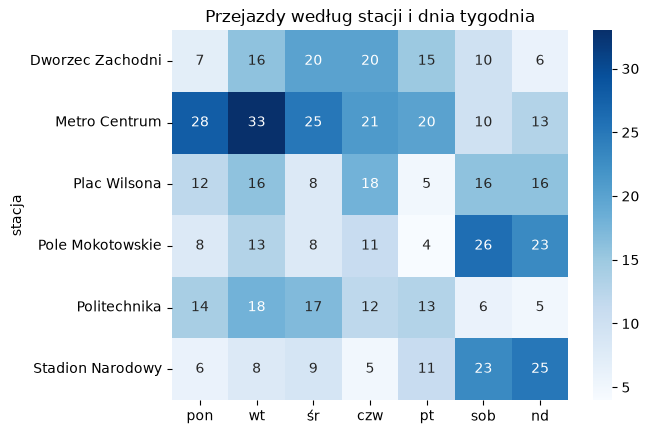

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(tabela, annot=True, fmt="d", cmap="Blues")
plt.title("Przejazdy według stacji i dnia tygodnia")
plt.show()

![Mapa ciepła liczby przejazdów według stacji i dnia tygodnia](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/obrazki/zajecia_2_heatmapa.png)

Od razu widać dwa światy: Metro Centrum, Politechnika i Dworzec Zachodni żyją
w dni robocze (dojazdy do pracy i na uczelnię), a Pole Mokotowskie i Stadion
Narodowy — w weekendy (rekreacja). To gotowa wskazówka dla wypożyczalni: rowery
trzeba w piątek wieczorem przewozić z centrum w stronę parków.

`margins=True` dokłada wiersz i kolumnę z sumami:

In [32]:
df.pivot_table(index="stacja", columns="rower", values="oplata", aggfunc="sum",
               margins=True, margins_name="razem")

rower,elektryczny,klasyczny,razem
stacja,,,
Dworzec Zachodni,62.0,16.0,78.0
Metro Centrum,52.0,38.0,90.0
Plac Wilsona,58.0,44.0,102.0
Pole Mokotowskie,66.0,19.0,85.0
Politechnika,36.0,17.0,53.0
Stadion Narodowy,82.0,36.0,118.0
razem,356.0,170.0,526.0


Rowery elektryczne to jedna trzecia przejazdów, ale dwie trzecie przychodu.

> 💡 **Puste pola w tabeli przestawnej**
>
> Jeśli jakaś kombinacja nie wystąpiła w danych (np. żadnego przejazdu
> elektrykiem z danej stacji w niedzielę), w tabeli pojawi się `NaN`. Przy
> zliczaniu i sumowaniu brak oznacza po prostu zero — dopisz wtedy
> `fill_value=0`.

### Format szeroki i długi: `melt`

Tabela przestawna produkuje **format szeroki** — każdy tydzień to osobna
kolumna:

In [33]:
tygodnie = df.pivot_table(index="stacja", columns="tydzien", values="id", aggfunc="count")
tygodnie = tygodnie.reset_index()
tygodnie

tydzien,stacja,36,37,38,39,40
0,Dworzec Zachodni,22,23,27,15,7
1,Metro Centrum,29,42,29,34,16
2,Plac Wilsona,15,30,21,21,4
3,Pole Mokotowskie,24,26,17,20,6
4,Politechnika,16,16,16,32,5
5,Stadion Narodowy,13,23,21,25,5


(`reset_index()` zamienia stację z indeksu z powrotem w zwykłą kolumnę.)

Taki format jest wygodny dla człowieka — dlatego tak wyglądają raporty
w Excelu. Ale do dalszej pracy w pandas lepszy jest **format długi**: jeden
wiersz = jedna obserwacja („na stacji X w tygodniu Y było Z przejazdów"). Ze
szerokiego robi go `melt`:

In [34]:
dlugi = tygodnie.melt(id_vars="stacja", var_name="tydzien", value_name="przejazdy")
print(dlugi.shape)
dlugi.head(8)

(30, 3)


,stacja,tydzien,przejazdy
0,Dworzec Zachodni,36,22
1,Metro Centrum,36,29
2,Plac Wilsona,36,15
3,Pole Mokotowskie,36,24
4,Politechnika,36,16
5,Stadion Narodowy,36,13
6,Dworzec Zachodni,37,23
7,Metro Centrum,37,42


- `id_vars` — kolumny, które zostają bez zmian (identyfikują wiersz),
- `var_name` — nazwa nowej kolumny, do której trafią **nazwy** dawnych kolumn
  (36, 37, …),
- `value_name` — nazwa kolumny na **wartości**.

6 stacji × 5 tygodni = 30 wierszy. `pivot_table` i `melt` to dwie strony tej
samej operacji:

![Format szeroki i długi oraz przejście między nimi przez melt i pivot_table](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/obrazki/zajecia_2_szeroki_dlugi.png)

Po co format długi? Bo na nim działa wszystko, co już znasz — `groupby`,
filtrowanie, `merge` — i wszystkie biblioteki do wykresów (seaborn, Plotly)
oczekują danych właśnie w tym kształcie. Ile przejazdów było w każdym tygodniu?

In [35]:
dlugi.groupby("tydzien")["przejazdy"].sum()

tydzien
36    119
37    160
38    131
39    147
40     43
Name: przejazdy, dtype: int64

Na formacie szerokim musiałbyś sumować pięć kolumn osobno. (Tydzień 40 jest
krótki, bo wrzesień kończy się w środę.)

> 💡 **Raport z Excela do analizy**
>
> W pracy często dostaniesz plik w formacie szerokim: miesiące, sklepy albo
> produkty w kolumnach. Pierwsze, co z nim robisz po wczytaniu, to `melt`.

### Zapis wyniku

In [36]:
df.to_csv("przejazdy_czyste.csv", index=False)

Czyste dane zapisujesz do **nowego** pliku, a surowe zostawiasz w spokoju. Jeśli
w czyszczeniu był błąd, poprawiasz kod i uruchamiasz go od nowa na surowych
danych. Na tym polega przewaga notatnika nad ręcznym poprawianiem w Excelu:
każdą decyzję widać i każdą można cofnąć.

## Ściągawka

| Chcę… | Kod |
|---|---|
| typy i braki naraz | `df.info()` |
| ile braków w kolumnach | `df.isna().sum()` |
| ile duplikatów | `df.duplicated().sum()` |
| duplikaty po kluczu | `df.duplicated(subset=["id"]).sum()` |
| pokazać duplikaty z oryginałami | `df[df.duplicated(keep=False)]` |
| usunąć duplikaty | `df = df.drop_duplicates()` |
| warianty tekstu (ze spacjami) | `df["kol"].unique()` |
| ujednolicić tekst | `df["kol"].str.strip().str.title()` (albo `.str.lower()`) |
| poprawić wybrane wartości | `df["kol"].replace({"stara": "nowa"})` |
| usunąć fragment tekstu | `df["kol"].str.replace(" zł", "")` |
| tekst na liczbę (śmieci → `NaN`) | `pd.to_numeric(df["kol"], errors="coerce")` |
| tekst na datę w danym formacie | `pd.to_datetime(df["kol"], format="%d.%m.%Y", errors="coerce")` |
| skleić dwie próby | `proba1.fillna(proba2)` |
| zamienić wartości spełniające warunek | `df.loc[df["kol"] < 0, "kol"] = np.nan` |
| uzupełnić medianą grupy | `df["kol"].fillna(df.groupby("grupa")["kol"].transform("median"))` |
| oznaczyć braki | `df["kol_brak"] = df["kol"].isna()` |
| część daty | `df["data"].dt.month`, `.dt.day_of_week`, `.dt.hour` |
| przedziały | `pd.cut(df["kol"], bins=[0, 20, 60], labels=["mało", "dużo"])` |
| tabela przestawna | `df.pivot_table(index="a", columns="b", values="c", aggfunc="sum", fill_value=0)` |
| sumy w tabeli przestawnej | `pivot_table(..., margins=True, margins_name="razem")` |
| szeroki → długi | `df.melt(id_vars="a", var_name="b", value_name="c")` |
| indeks z powrotem w kolumnę | `df.reset_index()` |
| zapisać wynik | `df.to_csv("plik.csv", index=False)` |

## Zadanie 2

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/metody_analizy_przetwarzania_i_wizualizacji_danych/zajecia_2/#zadanie-2-sprzatanie-po-stazyscie-12-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.